# Section 6: Exploratory Data Analysis

**Contents**

[Commands at a glance](#Commands-at-a-glance)

1. [Filtering](#1.-Filtering)
2. [Sorting](#2.-Sorting)
3. [Group by](#3.-Group-By)
4. [Pandas plots](#4.-Pandas-Plots)
5. [Pair plot](#5.-Pair-Plot)
6. [More plots](#6.-More-Plots)

### Learning objectives
Define the population behind a filtered result, aggregate at a stated grain, choose plots for a question, and distinguish descriptive association from explanation. Follow the original grocery, happiness, and student examples; each answers a different kind of question.

Optional source: lecture PDF pp. 132–160. Optional further reading: the [study guide](../../docs/study_guide.md), [pandas/NumPy reference](../../docs/reference/pandas_numpy.md), and [glossary](../../docs/reference/glossary.md). **Predict:** when will an operation reduce observations, reduce columns, or merely reorder them?

### Commands at a glance

| Task | Commands used | What to remember |
| --- | --- | --- |
| Filter and select | `df[mask]`, `.loc[mask, columns]`, `&`, `.str.strip()` | Keep matching rows or selected columns, combine two conditions, or trim labels before matching. |
| Sort results | `.sort_values()`, `.head()` | Order rows by one or more columns, then take the first few. |
| Summarize groups | `.groupby()`, `.sum()`, `.count()`, `.agg()`, `.reset_index()` | Calculate group totals or nonmissing counts, run several summaries, and turn group labels back into columns. |
| Find a group's top row | `.sort_values(..., ascending=False).groupby(...).head(1)` | Sort highest first, then keep the first whole row per group so each item stays paired with its price. |
| Compare category averages | `.mean()`, `.plot.bar()`, `.plot.barh()` | Compute group means and compare them with vertical or horizontal bars. |
| Plot trends | `.isin()`, `.iloc[]`, `.pivot()`, `.plot.line()`, `.plot()` | Match countries, select columns by position, then reshape and plot one series per country. |
| Inspect distributions | `.value_counts()`, `.sort_index()`, `.round()`, `sns.histplot()` | Count values and order the labels, optionally rounding first, or plot a histogram. |
| Explore relationships | `sns.pairplot()`, `sns.scatterplot()`, `.corr()` | Compare several variable pairs, inspect one pair, or measure linear association. |

## 1. Filtering

| Operation | Effect on rows or grain |
| --- | --- |
| Filter | Selects a population of rows |
| Sort | Reorders rows without selecting them |
| Group and aggregate | Produces a result at the chosen grouping grain |

The opening read uses the **bundled trusted** `../../data/groceries_with_new_columns.pkl`. The cleaning demo's optional regenerated output now goes separately to `../../artifacts/`; it does not overwrite this input. Never load pickles from untrusted sources.

A filter changes the population being described: low-inventory snacks are not representative of all groceries. State both conditions and the denominator when reporting a percentage. `&` combines elementwise boolean masks and needs parentheses around comparisons; Python `and` is not a substitute. `.loc[mask, columns]` makes row and column selection explicit. **Predict:** why might matching `Snacks` initially return nothing? Inspect whitespace before assuming there are no such products. `.str.strip()` persists here because its result is assigned back.

In [1]:
import pandas as pd

groceries = pd.read_pickle('../../data/groceries_with_new_columns.pkl')
groceries.head()

,Product_ID,Product_ID_Num,Category,Subcategory,Item,Organic,Price_Dollars,Inventory,Percent Inventory,Low Inventory,Last_Updated,Last_Updated_Time,Next_Scheduled_Shipment,Shipment_Date_DOW
0,P100010,100010,Produce,Fruit,Apple,False,1.50,349,7.2,,2023-06-12 15:35:00,15:35:00,2023-06-15,Thursday
1,P100011,100011,Produce,Fruit,Banana,False,0.40,500,10.3,,2023-06-12 18:30:00,18:30:00,2023-06-15,Thursday
2,P100012,100012,Produce,Fruit,Grapes,False,4.00,200,4.1,,2023-06-12 17:22:00,17:22:00,2023-06-15,Thursday
3,P100013,100013,Produce,Fruit,Grapefruit,False,0.99,50,1.0,,2023-06-12 16:29:00,16:29:00,2023-06-15,Thursday
4,P100014,100014,Produce,Fruit,Organic Strawberries,True,3.99,148,3.0,,2023-06-12 18:10:00,18:10:00,2023-06-15,Thursday


**A comparison makes the mask; indexing applies it.** `groceries['Low Inventory']` reads the column (its name contains a space). `== 'Low Inventory'` checks each value against the text label, producing one Boolean per row. `groceries[mask]` keeps matching rows and all columns. The next cell uses `groceries.loc[mask, ['Price_Dollars', 'Inventory']]` to keep the same rows but only the two named columns: rows go before the comma and columns after it. Neither selection changes `groceries`.

In [2]:
# filter on low inventory
groceries[groceries['Low Inventory'] == 'Low Inventory']

,Product_ID,Product_ID_Num,Category,Subcategory,Item,Organic,Price_Dollars,Inventory,Percent Inventory,Low Inventory,Last_Updated,Last_Updated_Time,Next_Scheduled_Shipment,Shipment_Date_DOW
15,P100025,100025,Produce,Dairy,Milk (Soy),False,4.49,32,0.7,Low Inventory,2023-06-13 08:37:00,08:37:00,2023-06-17,Saturday
17,P100027,100027,Pantry,Snacks,Apple Sauce - organic,True,1.50,27,0.6,Low Inventory,2023-06-10 12:02:00,12:02:00,2023-06-24,Saturday
20,P100030,100030,Pantry,Snacks,Raisins,False,2.99,5,0.1,Low Inventory,2023-06-10 12:38:00,12:38:00,2023-06-24,Saturday


In [3]:
# compare with .loc
groceries.loc[groceries['Low Inventory'] == 'Low Inventory', ['Price_Dollars', 'Inventory']]

,Price_Dollars,Inventory
15,4.49,32
17,1.50,27
20,2.99,5


**Why can a label that looks right fail to match?** `' Snacks'` and `'Snacks'` are different strings. The next cells inspect an individual value and use `.str.strip()` to remove leading and trailing whitespace from each label, not spaces inside a label. The single `=` writes the cleaned column back, so filters run after that line see the updated labels.

In [4]:
# filter on the snacks subcategory
groceries[groceries.Subcategory == 'Snacks']

,Product_ID,Product_ID_Num,Category,Subcategory,Item,Organic,Price_Dollars,Inventory,Percent Inventory,Low Inventory,Last_Updated,Last_Updated_Time,Next_Scheduled_Shipment,Shipment_Date_DOW


In [5]:
# check one value
groceries.Subcategory[15]

' Dairy'

In [6]:
# strip then filter
groceries.Subcategory = groceries.Subcategory.str.strip()

**Combine two masks with `&` (row-by-row “and”).** The two parenthesized comparisons each produce a Boolean Series. A row is kept only when both are `True`: it is a snack *and* has low inventory. Keep the parentheses around each comparison so Python evaluates them before `&`. Do not use Python's `and` here: it expects a single truth value from each side, not one per row. `mask = ...` names the result so the next two selections can reuse it.

For a snack with plenty of stock, the two tests are `False` (low inventory) and `True` (snack). `&` excludes it; `|` would include it because at least one test passes. To see products outside an existing selection, `groceries.loc[~mask]` inverts the mask. For example:

```python
import pandas as pd

example = pd.DataFrame({"kind": ["Snack", "Snack", "Fruit"], "stock": [5, 30, 5]})
snack = example["kind"] == "Snack"
low_stock = example["stock"] < 10
example.loc[snack & low_stock]    # row 0: snack and low stock
example.loc[snack | low_stock]    # rows 0, 1, 2: snack or low stock (or both)
example.loc[~low_stock, "kind"]   # row 1's kind: "Snack"
```

In [7]:
# filter on low inventory snacks
mask = (groceries['Low Inventory'] == 'Low Inventory') & (groceries.Subcategory == 'Snacks')
groceries[mask]

,Product_ID,Product_ID_Num,Category,Subcategory,Item,Organic,Price_Dollars,Inventory,Percent Inventory,Low Inventory,Last_Updated,Last_Updated_Time,Next_Scheduled_Shipment,Shipment_Date_DOW
17,P100027,100027,Pantry,Snacks,Apple Sauce - organic,True,1.50,27,0.6,Low Inventory,2023-06-10 12:02:00,12:02:00,2023-06-24,Saturday
20,P100030,100030,Pantry,Snacks,Raisins,False,2.99,5,0.1,Low Inventory,2023-06-10 12:38:00,12:38:00,2023-06-24,Saturday


In [8]:
# filter rows and columns
groceries.loc[mask, ['Subcategory', 'Item', 'Inventory']]

,Subcategory,Item,Inventory
17,Snacks,Apple Sauce - organic,27
20,Snacks,Raisins,5


## 2. Sorting

`sort_values` reorders rows; it does not filter them. The chained `head()` selects only the first few rows of that sorted result. Unassigned sorts leave `groceries` unchanged. Ties need an explicit secondary key if a reproducible single winner matters. See [sort_values](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html).

**Sort by one key, then break ties with another.** The first cell sorts prices from low to high (the default `ascending=True`); `ascending=False` reverses that order. With multiple keys, the second key orders rows tied on the first. For example, `sort_values(['Subcategory', 'Price_Dollars'], ascending=[True, False])` sorts subcategories alphabetically and puts the highest prices first *within* each subcategory. This is not the same as sorting the whole table by price.

In [9]:
# sort by price
groceries.sort_values('Price_Dollars').head()

,Product_ID,Product_ID_Num,Category,Subcategory,Item,Organic,Price_Dollars,Inventory,Percent Inventory,Low Inventory,Last_Updated,Last_Updated_Time,Next_Scheduled_Shipment,Shipment_Date_DOW
1,P100011,100011,Produce,Fruit,Banana,False,0.40,500,10.3,,2023-06-12 18:30:00,18:30:00,2023-06-15,Thursday
9,P100019,100019,Produce,Vegetable,Cucumber,False,0.99,230,4.7,,2023-06-12 17:47:00,17:47:00,2023-06-15,Thursday
3,P100013,100013,Produce,Fruit,Grapefruit,False,0.99,50,1.0,,2023-06-12 16:29:00,16:29:00,2023-06-15,Thursday
16,P100026,100026,Produce,Dairy,Yogurt,False,1.00,432,8.9,,2023-06-13 08:41:00,08:41:00,2023-06-17,Saturday
17,P100027,100027,Pantry,Snacks,Apple Sauce - organic,True,1.50,27,0.6,Low Inventory,2023-06-10 12:02:00,12:02:00,2023-06-24,Saturday


In [10]:
# sort by price descending
groceries.sort_values('Price_Dollars', ascending=False).head()

,Product_ID,Product_ID_Num,Category,Subcategory,Item,Organic,Price_Dollars,Inventory,Percent Inventory,Low Inventory,Last_Updated,Last_Updated_Time,Next_Scheduled_Shipment,Shipment_Date_DOW
23,P100033,100033,Frozen,Frozen Fruit,Frozen Blueberries,False,10.99,162,3.3,,2023-05-28 22:14:00,22:14:00,2023-06-28,Wednesday
11,P100021,100021,Produce,Meat,Chicken (Organic),True,10.49,284,5.8,,2023-06-13 07:20:00,07:20:00,2023-06-17,Saturday
10,P100020,100020,Produce,Meat,Beef,False,8.99,145,3.0,,2023-06-13 07:00:00,07:00:00,2023-06-17,Saturday
12,P100022,100022,Produce,Meat,Turkey,False,7.99,188,3.9,,2023-06-13 07:32:00,07:32:00,2023-06-17,Saturday
24,P100034,100034,Frozen,Frozen Fruit,Frozen Pineapple,False,7.96,178,3.7,,2023-05-28 22:11:00,22:11:00,2023-06-28,Wednesday


In [11]:
# sort on multiple columns
groceries.sort_values(['Subcategory', 'Price_Dollars']).head(10)

,Product_ID,Product_ID_Num,Category,Subcategory,Item,Organic,Price_Dollars,Inventory,Percent Inventory,Low Inventory,Last_Updated,Last_Updated_Time,Next_Scheduled_Shipment,Shipment_Date_DOW
16,P100026,100026,Produce,Dairy,Yogurt,False,1.00,432,8.9,,2023-06-13 08:41:00,08:41:00,2023-06-17,Saturday
14,P100024,100024,Produce,Dairy,Eggs,False,3.29,234,4.8,,2023-06-13 08:54:00,08:54:00,2023-06-17,Saturday
13,P100023,100023,Produce,Dairy,Butter,False,3.50,400,8.2,,2023-06-13 08:35:00,08:35:00,2023-06-17,Saturday
15,P100025,100025,Produce,Dairy,Milk (Soy),False,4.49,32,0.7,Low Inventory,2023-06-13 08:37:00,08:37:00,2023-06-17,Saturday
24,P100034,100034,Frozen,Frozen Fruit,Frozen Pineapple,False,7.96,178,3.7,,2023-05-28 22:11:00,22:11:00,2023-06-28,Wednesday
23,P100033,100033,Frozen,Frozen Fruit,Frozen Blueberries,False,10.99,162,3.3,,2023-05-28 22:14:00,22:14:00,2023-06-28,Wednesday
22,P100032,100032,Frozen,Frozen Snacks,Spinach Dip,False,4.96,76,1.6,,2023-05-28 22:05:00,22:05:00,2023-06-28,Wednesday
21,P100031,100031,Frozen,Frozen Snacks,Chicken Nuggets,False,6.99,85,1.8,,2023-05-28 22:02:00,22:02:00,2023-06-28,Wednesday
1,P100011,100011,Produce,Fruit,Banana,False,0.40,500,10.3,,2023-06-12 18:30:00,18:30:00,2023-06-15,Thursday
3,P100013,100013,Produce,Fruit,Grapefruit,False,0.99,50,1.0,,2023-06-12 16:29:00,16:29:00,2023-06-15,Thursday


In [12]:
# chain on sort_values
groceries[groceries['Low Inventory'] == 'Low Inventory'].sort_values('Price_Dollars')

,Product_ID,Product_ID_Num,Category,Subcategory,Item,Organic,Price_Dollars,Inventory,Percent Inventory,Low Inventory,Last_Updated,Last_Updated_Time,Next_Scheduled_Shipment,Shipment_Date_DOW
17,P100027,100027,Pantry,Snacks,Apple Sauce - organic,True,1.50,27,0.6,Low Inventory,2023-06-10 12:02:00,12:02:00,2023-06-24,Saturday
20,P100030,100030,Pantry,Snacks,Raisins,False,2.99,5,0.1,Low Inventory,2023-06-10 12:38:00,12:38:00,2023-06-24,Saturday
15,P100025,100025,Produce,Dairy,Milk (Soy),False,4.49,32,0.7,Low Inventory,2023-06-13 08:37:00,08:37:00,2023-06-17,Saturday


## 3. Group By

### State the aggregation grain and measure
`groupby('Category')` creates a grouping object; aggregation produces one result per category. Grouping by category and subcategory produces one result per pair. Inventory `sum()` counts stock units. Inventory `count()` counts nonmissing inventory entries—not unique items. Use `size()` for rows (including missing inventory), and `nunique()` on a product key for distinct products. These counts coincide only under additional assumptions. Missing grouping keys are excluded by default.

**Predict before the intentionally incorrect example:** columnwise `max()` can select the alphabetically greatest item name and the highest price from different rows. Sorting by price then taking the first row per group retains the item's association with its price; ties still require a policy. See [groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html).

In [13]:
# group by category
groceries.groupby('Category')

In [14]:
# group by category and show total inventory
groceries.groupby('Category')['Inventory'].sum()

Category
Frozen      501
Pantry      737
Produce    3619
Name: Inventory, dtype: int64

In [15]:
# group by category and count nonmissing inventory values
groceries.groupby('Category')['Inventory'].count()

Category
Frozen      4
Pantry      4
Produce    17
Name: Inventory, dtype: int64

**Follow the shape of the grouped result.** `groupby(['Category', 'Subcategory'])['Inventory']` selects inventory values within each category–subcategory pair. `.count()` gives one count per pair, with the two group labels in the index. `.reset_index()` turns those labels back into ordinary columns for a flat table. `.agg(['sum', 'count'])` computes both summaries on the same groups: the sum answers “how many units?” and the count answers “how many nonmissing inventory entries?”

In [16]:
# group by category and subcategory and count nonmissing inventory values
groceries.groupby(['Category', 'Subcategory'])['Inventory'].count().reset_index()

,Category,Subcategory,Inventory
0,Frozen,Frozen Fruit,2
1,Frozen,Frozen Snacks,2
2,Pantry,Snacks,4
3,Produce,Dairy,4
4,Produce,Fruit,6
5,Produce,Meat,3
6,Produce,Vegetable,4


In [17]:
# group by category and subcategory and summarize inventory
groceries.groupby(['Category', 'Subcategory'])['Inventory'].agg(['sum', 'count']).reset_index()

,Category,Subcategory,sum,count
0,Frozen,Frozen Fruit,340,2
1,Frozen,Frozen Snacks,161,2
2,Pantry,Snacks,737,4
3,Produce,Dairy,1098,4
4,Produce,Fruit,1346,6
5,Produce,Meat,617,3
6,Produce,Vegetable,558,4


In [18]:
# group by category and show max priced item
groceries.groupby('Category')['Price_Dollars'].max().reset_index()

,Category,Price_Dollars
0,Frozen,10.99
1,Pantry,5.39
2,Produce,10.49


In [19]:
# group by category and show the item -- THIS IS INCORRECT!
groceries.groupby('Category')[['Item','Price_Dollars']].max()

,Item,Price_Dollars
Category,,
Frozen,Spinach Dip,10.99
Pantry,Raisins,5.39
Produce,Yogurt,10.49


In [20]:
# this is correct
(groceries[['Category', 'Item', 'Price_Dollars']]
 .sort_values('Price_Dollars', ascending=False)
 .groupby('Category').head(1))

,Category,Item,Price_Dollars
23,Frozen,Frozen Blueberries,10.99
11,Produce,Chicken (Organic),10.49
19,Pantry,Cookies (Oatmeal),5.39


## 4. Pandas Plots

| Plot | Useful question |
| --- | --- |
| Bar | How do categories compare? |
| Line | How does a measure change over ordered time? |
| Histogram | What is the distribution of a numeric variable? |
| Scatter | How do two numeric variables vary together? |

The grocery bars show mean product price by subcategory, not total spend or an inventory-weighted mean. A horizontal sorted chart improves comparison but does not change the underlying statistic. Ask whether group sample sizes differ before interpreting a large mean.

For happiness, each line connects country/year scores; confirm chronological ordering and missing years before interpreting a trend. `pivot` assumes one score per country/year pair and raises on duplicate pairs; do not silently average duplicates without understanding them. The positional column slices rely on the supplied schema. See [pivot](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html).

In [21]:
groceries.head()

,Product_ID,Product_ID_Num,Category,Subcategory,Item,Organic,Price_Dollars,Inventory,Percent Inventory,Low Inventory,Last_Updated,Last_Updated_Time,Next_Scheduled_Shipment,Shipment_Date_DOW
0,P100010,100010,Produce,Fruit,Apple,False,1.50,349,7.2,,2023-06-12 15:35:00,15:35:00,2023-06-15,Thursday
1,P100011,100011,Produce,Fruit,Banana,False,0.40,500,10.3,,2023-06-12 18:30:00,18:30:00,2023-06-15,Thursday
2,P100012,100012,Produce,Fruit,Grapes,False,4.00,200,4.1,,2023-06-12 17:22:00,17:22:00,2023-06-15,Thursday
3,P100013,100013,Produce,Fruit,Grapefruit,False,0.99,50,1.0,,2023-06-12 16:29:00,16:29:00,2023-06-15,Thursday
4,P100014,100014,Produce,Fruit,Organic Strawberries,True,3.99,148,3.0,,2023-06-12 18:10:00,18:10:00,2023-06-15,Thursday


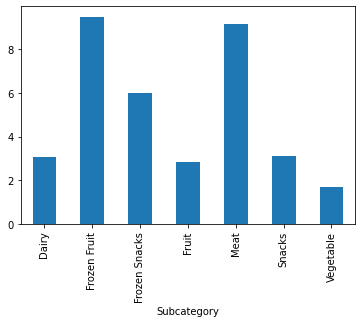

In [22]:
# create a bar chart
groceries.groupby('Subcategory')['Price_Dollars'].mean().plot.bar();

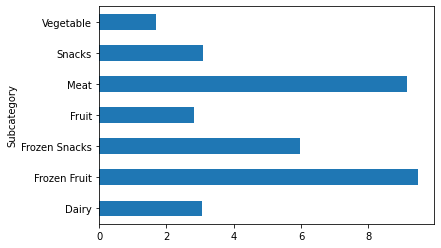

In [23]:
# create a horizontal bar chart
groceries.groupby('Subcategory')['Price_Dollars'].mean().plot.barh();

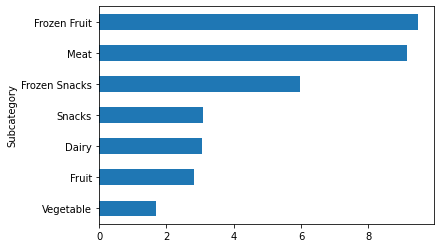

In [24]:
# create a horizontal bar chart with sorted values
groceries.groupby('Subcategory')['Price_Dollars'].mean().sort_values().plot.barh();

In [25]:
import pandas as pd

happiness = pd.read_csv('../../data/happiness_survey_data.csv')
happiness.head()

,country_name,year,happiness_score,social_support,freedom_to_make_life_choices,healthy_life_expectancy_at_birth
0,Afghanistan,2008,3.723590,0.450662,0.718114,50.500000
1,Afghanistan,2009,4.401778,0.552308,0.678896,50.799999
2,Afghanistan,2010,4.758381,0.539075,0.600127,51.099998
3,Afghanistan,2011,3.831719,0.521104,0.495901,51.400002
4,Afghanistan,2012,3.782938,0.520637,0.530935,51.700001


**Separate filtering, positional selection, and reshaping.** First filter by country. In `.iloc[:, 1:3]`, `.iloc` uses integer positions, `:` before the comma keeps all remaining rows, and `1:3` takes column positions `1` and `2` (the stop is excluded). The multi-country version uses `.isin(...)` to match any of the listed country names and takes the first three columns with `.iloc[:, :3]`.

`pivot(index='year', columns='country_name', values='happiness_score')` then turns one row per year–country observation into one row per year and one column per country. The score goes at the intersection, so plotting the wide table draws one series per country. A missing year–country pair leaves a gap; a duplicate pair raises an error because `pivot` does not decide how to combine multiple scores.

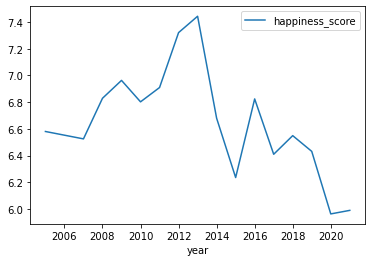

In [26]:
# create a line chart for Mexico's happiness scores
# iloc selects positions 1 and 2; the end position 3 is exclusive.
happiness[happiness.country_name == 'Mexico'].iloc[:, 1:3].plot.line(x='year', y='happiness_score');

In [27]:
# Filter to three countries; iloc[:, :3] retains the first three columns.
# pivot puts years on rows, countries on columns, and scores in the cells.
# Example: 2 years x 3 countries = 6 long rows -> 2 wide rows, 3 series.
# Missing year/country combinations become NaN; plot draws each country column.
(happiness[happiness.country_name.isin(['Canada', 'Mexico','United States'])]
                                 .iloc[:, :3]
                                 .pivot(index='year', columns='country_name', values='happiness_score'))

country_name,Canada,Mexico,United States
year,,,
2005,7.418048,6.580658,NaN
2006,NaN,NaN,7.181794
2007,7.481753,6.525378,7.512688
2008,7.485604,6.829036,7.280386
2009,7.487824,6.962819,7.158032
2010,7.650346,6.802389,7.163616
2011,7.426054,6.909515,7.115139
2012,7.415144,7.320185,7.026227
2013,7.593794,7.442546,7.249285


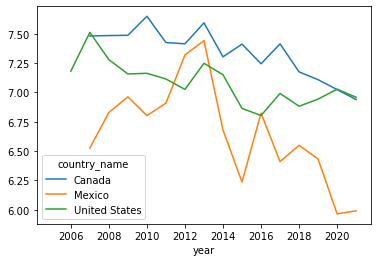

In [28]:
# create a line chart with multiple lines
(happiness[happiness.country_name.isin(['Canada', 'Mexico','United States'])]
                                 .iloc[:, :3]
                                 .pivot(index='year', columns='country_name', values='happiness_score')
                                 .plot());

### Reading distribution shapes

A **distribution** describes which values a variable can take and how common they are. A histogram summarizes what you observed in a sample; the four plots below show what different probability models predict. Start with what one observation represents and what values are possible, not just what shape the plot resembles.

| Model | What one observation represents | What to look for |
| --- | --- | --- |
| **Normal** | One person's height, measured on a continuous scale | A symmetric bell: values near the mean are more common, and values farther from it are rarer on both sides. |
| **Binomial** | The number of clicks from 20 customers, each independently clicking with the same 10% chance | Whole numbers from 0 to 20. A few clicks are common, but there's a right tail of less likely larger counts. |
| **Discrete uniform** | The face showing on one roll of a fair six-sided die | Six equally tall bars: each outcome has probability 1/6. |
| **Poisson** | The number of cancellations in one day, assuming events occur independently at a steady average rate of two per day | Whole numbers starting at 0, with no fixed maximum in the model. Two is the average, not a daily quota; some days have zero and others have more than two. |

The click count has a fixed number of opportunities (20); the Poisson example counts events in a fixed time window instead. Both plots lean right here, so shape alone can't tell you which model fits. Each bar gives the probability of that exact count or outcome. For a continuous variable like height, probability is **area under the curve over an interval**, not the curve's height at a point.

### Normal distribution: center, spread, and the empirical rule

The **mean** marks the center of a normal curve. Changing it shifts the whole curve left or right. The **standard deviation (SD)** measures spread in the same units as the data. With the same mean, a larger SD makes the curve wider and lower: the same total probability is spread over a wider range. In the height example, the mean is 64 inches and one SD is 2.2 inches, so the first interval is `64 − 2.2` to `64 + 2.2` inches.

The shaded curve below shows the **68–95–99.7 rule**: in a normal distribution, about 68% of values lie within one SD of the mean, 95% within two, and 99.7% within three. These intervals are nested: the 95% includes the middle 68%. The percentages describe what the model predicts, not exact counts you must see in a sample.

| Central range | Height interval | Approximate probability |
| --- | --- | --- |
| Mean ± 1 SD | 61.8–66.2 inches | 68% |
| Mean ± 2 SD | 59.6–68.4 inches | 95% |
| Mean ± 3 SD | 57.4–70.6 inches | 99.7% |

For example, 69 inches is outside the two-SD interval but inside the three-SD interval. Only about 5% of heights are outside the two-SD interval under this model, split evenly between the two tails. Going past three SDs is a reason to investigate the units, measurement, or population—not to delete the observation automatically.

**When reading the next pair plot:** use the diagonal histograms to check for symmetry, multiple peaks, and unusual values. If a histogram is **skewed**, name the side with the longer tail: right skew means a tail toward larger values, even if most observations are small. Don't apply the empirical rule just because a variable is numeric or has a mean and SD. If its shape or the way the data was collected makes a normal model doubtful, report what you actually observe instead.

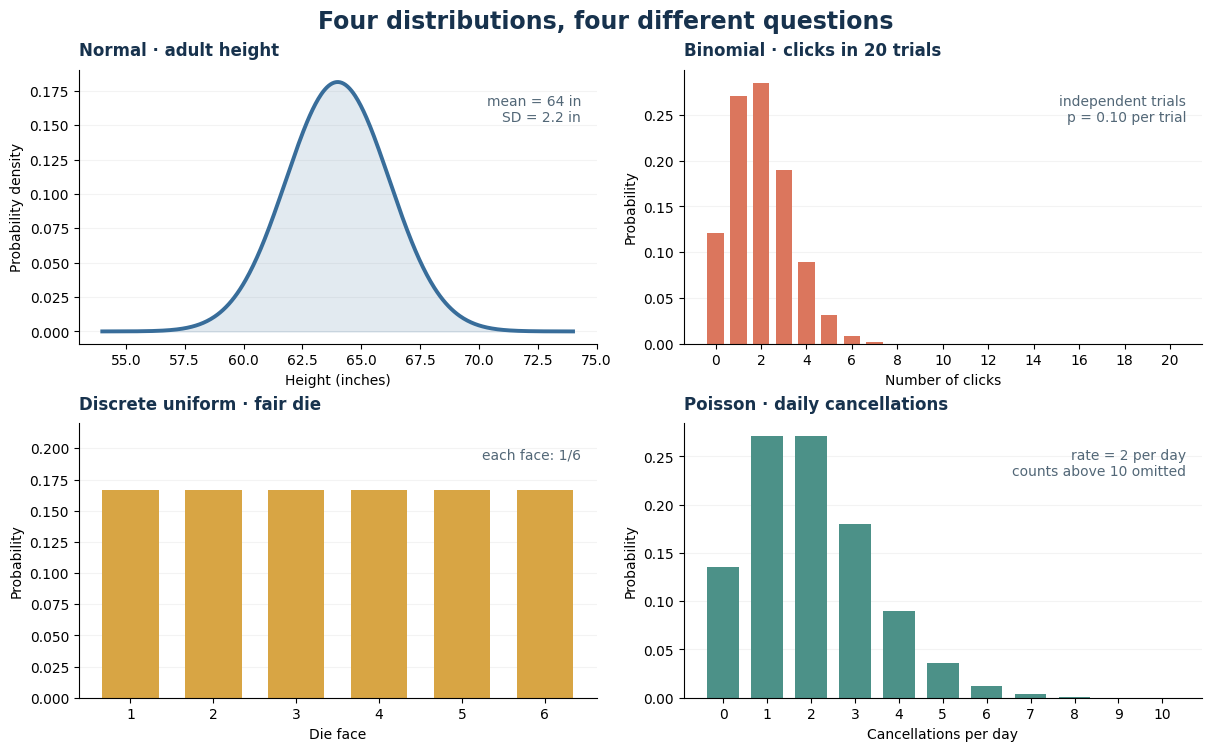

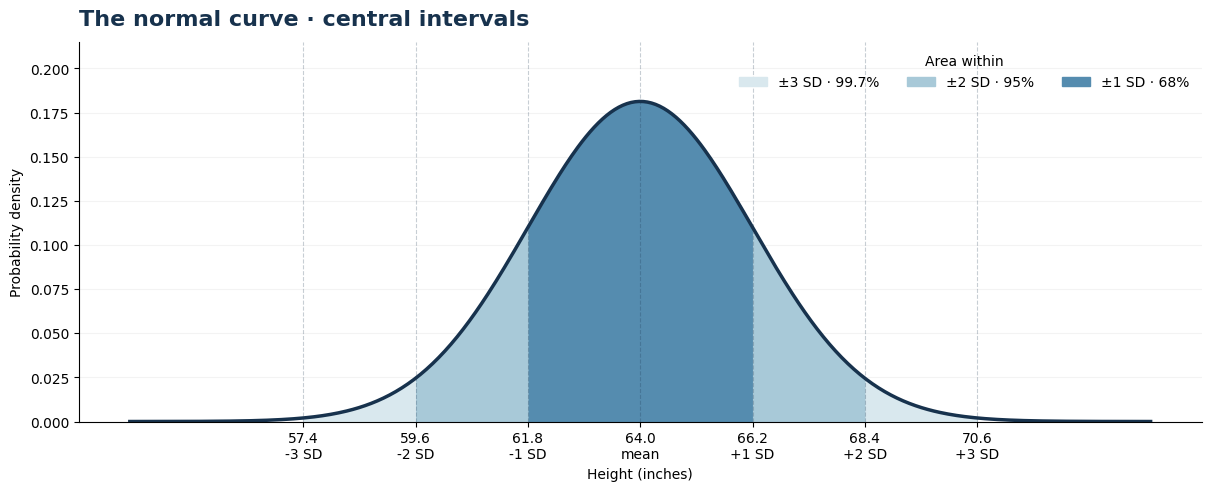

In [ ]:
# Standalone theoretical examples: no course dataset is needed.
import math
import numpy as np
import matplotlib.pyplot as plt

ink, muted = "#17324d", "#526777"
blue, coral, gold, teal = "#386d9a", "#db765d", "#d8a544", "#4c9188"
fig, axes = plt.subplots(2, 2, figsize=(12, 7.4), layout="constrained")
fig.suptitle("Four distributions, four different questions", fontsize=17,
             fontweight="bold", color=ink)

# Continuous normal density: height in inches.
x = np.linspace(54, 74, 500)
mu, sigma = 64, 2.2
density = np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
ax = axes[0, 0]
ax.plot(x, density, color=blue, lw=2.8)
ax.fill_between(x, density, color=blue, alpha=.14)
ax.set(title="Normal · adult height", xlabel="Height (inches)", ylabel="Probability density")
ax.text(.97, .91, "mean = 64 in\nSD = 2.2 in", transform=ax.transAxes,
        ha="right", va="top", color=muted)

# Number of clicks in 20 independent trials, each with probability 0.10.
k = np.arange(21)
binomial = [math.comb(20, int(i)) * .1**i * .9**(20-i) for i in k]
ax = axes[0, 1]
ax.bar(k, binomial, color=coral, width=.72)
ax.set(title="Binomial · clicks in 20 trials", xlabel="Number of clicks", ylabel="Probability")
ax.set_xticks(np.arange(0, 21, 2))
ax.text(.97, .91, "independent trials\np = 0.10 per trial", transform=ax.transAxes,
        ha="right", va="top", color=muted)

# A fair die gives each face the same probability.
faces = np.arange(1, 7)
ax = axes[1, 0]
ax.bar(faces, np.full(6, 1/6), color=gold, width=.68)
ax.set(title="Discrete uniform · fair die", xlabel="Die face", ylabel="Probability",
       ylim=(0, .22), xticks=faces)
ax.text(.97, .91, "each face: 1/6", transform=ax.transAxes,
        ha="right", va="top", color=muted)

# Poisson counts have no upper bound; the plotted tail is truncated after 10.
k = np.arange(11)
poisson = [math.exp(-2) * 2**int(i) / math.factorial(int(i)) for i in k]
ax = axes[1, 1]
ax.bar(k, poisson, color=teal, width=.72)
ax.set(title="Poisson · daily cancellations", xlabel="Cancellations per day",
       ylabel="Probability", xticks=k)
ax.text(.97, .91, "rate = 2 per day\ncounts above 10 omitted", transform=ax.transAxes,
        ha="right", va="top", color=muted)

for ax in axes.flat:
    title = ax.get_title()
    ax.set_title("")
    ax.set_title(title, loc="left", fontweight="bold", color=ink, pad=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=.15)
    ax.set_axisbelow(True)
plt.show()

# Nested central intervals under the same normal height model.
fig, ax = plt.subplots(figsize=(12, 4.8), layout="constrained")
ax.plot(x, density, color=ink, lw=2.5)
for spread, color, label in [(3, "#d9e8ee", "±3 SD · 99.7%"),
                              (2, "#a8c9d8", "±2 SD · 95%"),
                              (1, "#558caf", "±1 SD · 68%")]:
    ax.fill_between(x, density, where=(x >= mu-spread*sigma) & (x <= mu+spread*sigma),
                    color=color, label=label)
for spread in range(-3, 4):
    position = mu + spread * sigma
    ax.axvline(position, color=ink, alpha=.24, lw=.8, ls="--")
ax.set_xticks([mu + i*sigma for i in range(-3, 4)],
              [f"{mu + i*sigma:.1f}\n{('mean' if i == 0 else f'{i:+d} SD')}" for i in range(-3, 4)])
ax.set(title="The normal curve · central intervals", xlabel="Height (inches)",
       ylabel="Probability density", ylim=(0, .215))
title = ax.get_title()
ax.set_title("")
ax.set_title(title, loc="left", fontsize=16, fontweight="bold", color=ink, pad=12)
ax.legend(title="Area within", frameon=False, loc="upper right", ncol=3)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=.15)
ax.set_axisbelow(True)
plt.show()

## 5. Pair Plot

Read diagonal panels as individual distributions and off-diagonal panels as pairwise relationships. **Predict:** which pair should show the clearest association, and what pattern would contradict that prediction? Look for curvature, clusters, and isolated points, not only straight-line trends. Many pairwise panels invite chance discoveries; a pattern is a hypothesis for follow-up rather than proof. See [seaborn.pairplot](https://seaborn.pydata.org/generated/seaborn.pairplot.html).

In [29]:
import seaborn as sns

student_data = pd.read_csv('../../data/student_data.csv')
student_data.head()

,Hours of Sleep,Hours Studied,Grade on Test,Grade in Class,Cups of Coffee
0,10.602667,4.586892,99,99.187294,5
1,8.172997,4.405120,72,67.070903,3
2,6.430132,0.519630,52,39.644696,4
3,7.963793,5.004348,80,61.843705,1
4,8.279421,2.984489,87,103.495002,0


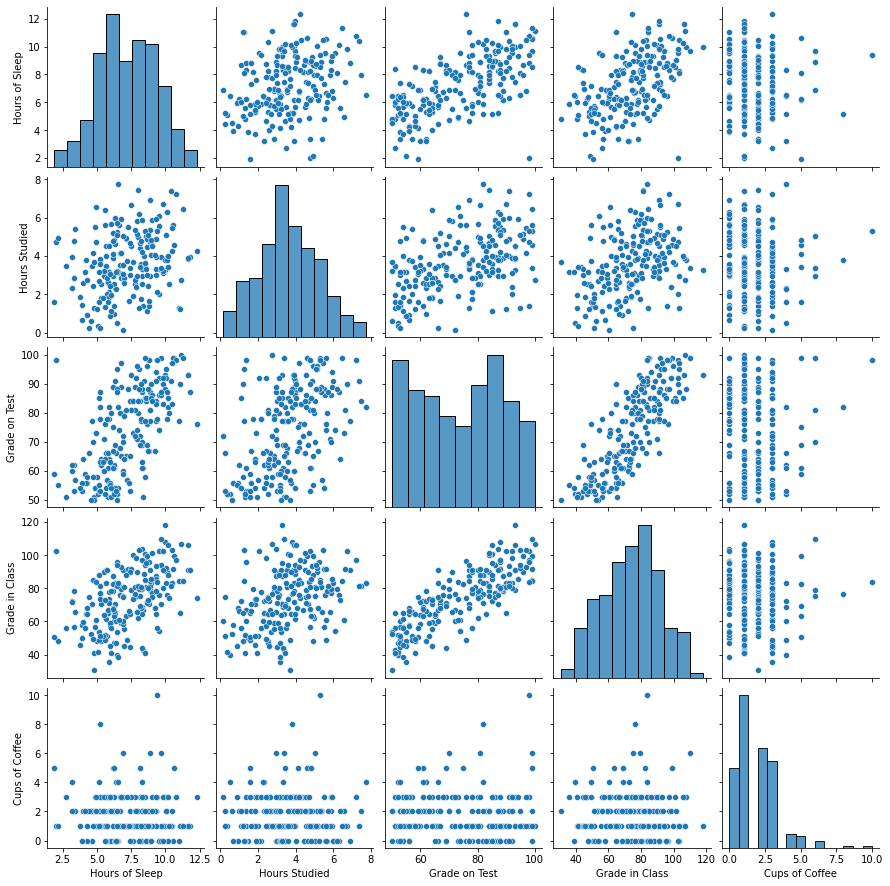

In [30]:
sns.pairplot(student_data);

## 6. More Plots

**Pearson correlation:** `r` ranges from -1 to 1. Its sign indicates direction and its magnitude indicates strength of a linear relationship. A value near zero does not exclude a nonlinear pattern.

Coffee cups are discrete counts; hours studied are continuous measurements. Rounding hours before `value_counts()` counts rounded values, not the original measurements. Investigating a student with very little sleep is a prompt to verify context, not automatic permission to drop that record.

**Frequency tables:** `value_counts(normalize=True)` gives proportions instead of counts: 3 of 4 observations becomes `0.75`. By default missing values are excluded from both the counts and the denominator. Use `dropna=False` to include them as their own entry. `.sort_index()` in the demo sorts by the observed values (cup counts), not by frequency.

**Histograms:** `bins=10` requests ten intervals; `binwidth=1` requests intervals one unit wide instead of fixing how many there are. For integer counts like cups of coffee, `discrete=True` centers a bar on each integer. For continuous measurements like hours, compare a few widths: very wide bins can hide peaks; very narrow bins can make noise look like a pattern.

The final correlation table summarizes linear association; correlation is not causation. Confounding, selection, reverse direction, and outliers can all explain a pattern. Pairwise missing-value handling may give different pairs different effective samples; a constant column has undefined correlation. The supplied student table is numeric, but on other schemas explicitly choose appropriate numeric measures rather than treating identifiers as continuous variables. See [DataFrame.corr](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html) and [modeling preparation](../../docs/reference/modeling_preparation.md).

In [31]:
student_data['Cups of Coffee']

0       5
1       3
2       4
3       1
4       0
       ..
195     2
196     1
197     1
198    10
199     2
Name: Cups of Coffee, Length: 200, dtype: int64

In [32]:
# frequency table of discrete data
(student_data['Cups of Coffee'].value_counts()
                               .sort_index())

0     35
1     67
2     44
3     38
4      6
5      5
6      3
8      1
10     1
Name: Cups of Coffee, dtype: int64

<AxesSubplot:xlabel='Cups of Coffee', ylabel='Count'>

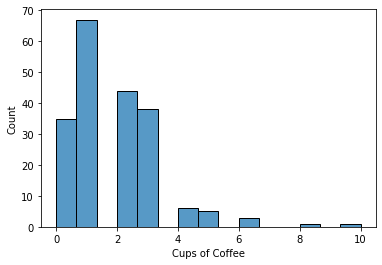

In [33]:
# histogram
sns.histplot(student_data['Cups of Coffee'])

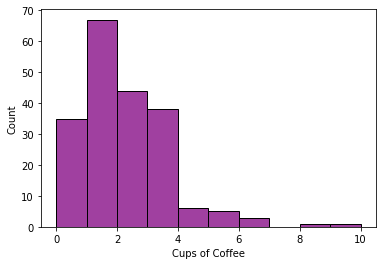

In [34]:
# another histogram
sns.histplot(student_data['Cups of Coffee'],
             bins=10, color='purple');

In [35]:
# frequency table of continuous data
student_data['Hours Studied'].round().value_counts().sort_index()

0.0     4
1.0    18
2.0    23
3.0    53
4.0    38
5.0    37
6.0    19
7.0     7
8.0     1
Name: Hours Studied, dtype: int64

<AxesSubplot:xlabel='Hours Studied', ylabel='Count'>

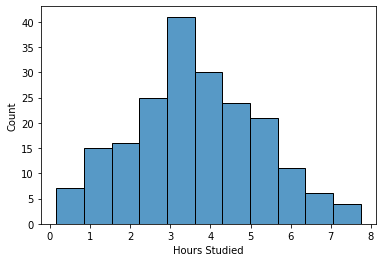

In [36]:
# histogram of continuous data
sns.histplot(student_data['Hours Studied'])

<AxesSubplot:xlabel='Hours of Sleep', ylabel='Grade on Test'>

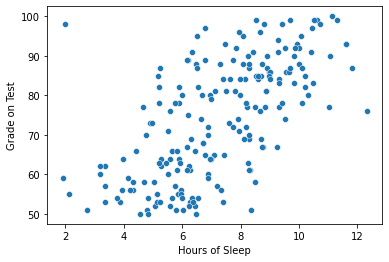

In [37]:
# scatter plot of data
sns.scatterplot(data=student_data, x='Hours of Sleep', y='Grade on Test')

In [38]:
# digging into an outlier
student_data[student_data['Hours of Sleep'] < 3]

,Hours of Sleep,Hours Studied,Grade on Test,Grade in Class,Cups of Coffee
12,2.000000,4.743829,98,102.670751,1
67,2.741172,3.498785,51,56.135378,3
97,2.130628,4.951326,55,48.417485,1
148,1.899843,1.584035,59,50.616890,5


### Read the scatterplot before the correlation table

Pearson's `r` measures how closely the points follow a straight line, not whether there is a relationship of any kind. Compare the straight lines and the U shape below. Each column within a plot is an `x` position; each dot is one observation.

```text
    Falling           U shape           Exact copy
y   r = -1            r = 0             r = +1
4   ● · · · ·         ● · · · ●         · · · · ●
3   · ● · · ·         · · · · ·         · · · ● ·
2   · · ● · ·         · · · · ·         · · ● · ·
1   · · · ● ·         · ● · ● ·         · ● · · ·
0   · · · · ●         · · ● · ·         ● · · · ·
x   0 1 2 3 4         0 1 2 3 4         0 1 2 3 4
```

- **Falling:** Larger `x` always goes with smaller `y`; the points lie on a downward line.
- **U shape:** `y` is fully determined by `x`, but the left half falls and the right half rises. Pearson's `r` is zero because there is no overall linear trend, not because the variables are unrelated.
- **Exact copy:** The two variables here have identical values. In the table below, the `1`s along the diagonal compare each variable to itself. A perfect correlation between *different* columns is worth checking for duplicated data or a unit conversion; it is not by itself proof of an error.

In [39]:
# correlation table
student_data.corr()

,Hours of Sleep,Hours Studied,Grade on Test,Grade in Class,Cups of Coffee
Hours of Sleep,1.000000,0.265404,0.637864,0.502397,-0.079643
Hours Studied,0.265404,1.000000,0.479153,0.374456,-0.020209
Grade on Test,0.637864,0.479153,1.000000,0.815721,-0.038804
Grade in Class,0.502397,0.374456,0.815721,1.000000,-0.035288
Cups of Coffee,-0.079643,-0.020209,-0.038804,-0.035288,1.000000


### Recap and optional transfer
An EDA claim should name its population, grain, measure, and uncertainty. Filtering defines who is included; aggregation defines what is counted; plots reveal patterns rather than establish causes.

1. Without mutating `groceries`, compare category-level `size()` with `['Inventory'].count()`. Explain why agreement does not establish that every product is unique.
2. Standalone missing-value example:
```python
import pandas as pd
example_eda = pd.DataFrame({'group': ['A', 'A', 'B'], 'stock': [2, None, 5]})
print(example_eda.groupby('group').size())
print(example_eda.groupby('group')['stock'].count())
```
Which result answers 'how many recorded rows', and which answers 'how many observed stock values'?